In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
import config
from src.utils import set_seed
set_seed(config.SEED)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.facecolor": "#F5F1E8", "figure.facecolor": "#F5F1E8", "axes.edgecolor": "#77766D",
                     "font.size": 10, "axes.titleweight": "bold"})
PALETTE = ["#344C3D", "#BD755A", "#C4A46A", "#899982", "#77766D", "#242723"]
sns.set_palette(PALETTE)
def note(txt):  # data-driven observation rendered as markdown
    display(Markdown("> **Observation.** " + txt))

# 08 — Medical Summarization

Summarize long biomedical articles locally. Systems compared:

| System | Type | Notes |
|---|---|---|
| **Lead-k** | extractive | first sentences up to ~the reference length — the classic strong baseline for news-style text |
| **TextRank (TF-IDF)** | extractive | `src.summarization.extractive_summary`; most central sentences |
| **T5-small (base)** | abstractive, zero-shot | `t5-small` with the `summarize:` prefix |
| **T5-small medical** | abstractive, transfer | `Falconsai/medical_summarization` (Apache-2.0), a T5-small *already fine-tuned by its authors* on medical text |

**What was and was not done.** I did **not fine-tune** any summarizer in this project (CPU-only machine, no training split downloaded — it is 2.2 GB). The "transfer learning" here is the *use of a pretrained, domain-fine-tuned model*, documented as such. Fine-tuning `t5-small` on the PubMed summarization training split is listed as future work.

**Corpus caveat.** The benchmark text is lower-cased and word-tokenised (`parkinson 's`), unlike the cased prose users paste into the app, and it needs its own sentence splitter (`sents_of`). The T5 models were not trained on this exact formatting, which may depress scores.

**Evaluation protocol.** Articles from the PubMed summarization **test** split; the author abstract is the reference. To fit CPU time, **15 articles** are scored and abstractive systems read only the **first 3 chunks (~1,500 tokens)** of each article, so scores are *lower bounds* for chunk-based systems and the sample is small (wide uncertainty — treat differences as indicative only).

In [2]:
import time, re, torch
import src.data as D
from collections import Counter
from src.preprocessing import split_sentences, STOPWORDS, tokenize
from src.summarization import extractive_summary, chunk_sentences, Summarizer, PREFIX
from src.evaluation import rouge_scores, numeric_consistency
from src.utils import save_json, update_json
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
torch.set_num_threads(2)
def sents_of(article):
    # corpus is lower-cased and pre-tokenised with ' . ' between sentences; the app's capital-letter splitter does not apply
    return [x.strip() for x in re.split(r"(?<= [.!?]) ", article) if x.strip()]
S = D.load_summarization_test(); S["w"] = S.article.str.split().str.len()
docs = S[(S.w > 1500) & (S.w < 6000)].sample(15, random_state=config.SEED).reset_index(drop=True)
print(docs.w.describe().round(0).to_dict(), "| reference words median:", int(docs.abstract.str.split().str.len().median()))

{'count': 15.0, 'mean': 3148.0, 'std': 1088.0, 'min': 1532.0, '25%': 2169.0, '50%': 3164.0, '75%': 4234.0, 'max': 4565.0} | reference words median: 233


## 1. Extractive vs abstractive

*Extractive* summaries copy sentences from the source → they cannot invent facts, but may be incoherent or redundant. *Abstractive* summaries are generated text → fluent and compact, but can **hallucinate** (wrong numbers, unsupported claims). Medical use makes that difference critical, which is why MediScope always shows extractive key sentences next to the generated summary.

## 2. Model selection and loading

`Falconsai/medical_summarization` is small (T5-small, ~60M parameters, ~240 MB), Apache-2.0 licensed and runs on CPU; PEGASUS-PubMed (568M) and BART-large variants are too heavy for a student laptop (≈2 GB+ weights, minutes per document). Both T5 models are loaded below; the medical one is saved to `artifacts/summarization/t5_medical/` for the Flask app.

In [3]:
class Sys:
    def __init__(self, hub_id, label):
        self.tok = AutoTokenizer.from_pretrained(hub_id); self.model = AutoModelForSeq2SeqLM.from_pretrained(hub_id).eval(); self.label = label
        self.hub_id = hub_id
    def n_tokens(self, t): return len(self.tok(t, add_special_tokens=False)["input_ids"])
    def gen(self, text, lo=48, hi=128, beams=2):
        enc = self.tok(PREFIX + text, return_tensors="pt", truncation=True, max_length=config.SUM_MAX_INPUT_TOKENS)
        with torch.no_grad(): out = self.model.generate(**enc, min_new_tokens=lo, max_new_tokens=hi, num_beams=beams, no_repeat_ngram_size=3, early_stopping=True)
        return self.tok.decode(out[0], skip_special_tokens=True).strip()
    def summarize(self, article, lo=48, hi=128, max_chunks=3):
        ch = chunk_sentences(sents_of(article), self.n_tokens)[:max_chunks]
        parts = [self.gen(" ".join(c), lo, hi) for c in ch]
        return " ".join(parts) if len(parts) == 1 else self.gen(" ".join(parts), lo, hi)
t0 = time.time(); med = Sys(config.HF_SUMMARIZER, "T5-small medical"); base = Sys("t5-small", "T5-small base")
print(f"loaded both models in {time.time()-t0:.0f}s | parameters: {sum(p.numel() for p in med.model.parameters())/1e6:.1f}M each")
d = config.ART_SUM / "t5_medical"; d.mkdir(parents=True, exist_ok=True); med.model.save_pretrained(d); med.tok.save_pretrained(d)

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

loaded both models in 45s | parameters: 60.5M each


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('D:\\MediScope\\artifacts\\summarization\\t5_medical\\tokenizer_config.json',
 'D:\\MediScope\\artifacts\\summarization\\t5_medical\\tokenizer.json')

## 3. Long-document chunking and token-length management

T5 encoders read ≤ 512 tokens here (`SUM_MAX_INPUT_TOKENS`). Articles are split into sentences, **packed greedily into ≤ 512-token chunks without cutting sentences**, each chunk is summarised, and — when there is more than one chunk — the concatenated chunk summaries are summarised again ("refine" pass).

In [4]:
art = docs.article.iloc[0]; chunks = chunk_sentences(sents_of(art), med.n_tokens)
tl = pd.DataFrame({"chunk": range(1, len(chunks) + 1), "sentences": [len(c) for c in chunks], "tokens": [med.n_tokens(" ".join(c)) for c in chunks]})
display(tl.T)
note(f"Example article ({docs.w.iloc[0]:,} words) → {len(chunks)} chunks of {tl.tokens.min()}–{tl.tokens.max()} tokens (limit {config.SUM_MAX_INPUT_TOKENS}). Evaluation uses only the first 3, "
     f"so {max(0, len(chunks) - 3)} chunks of this article are never seen by the abstractive systems — an explicit limitation.")

,0,1,2,3,4,5,6
chunk,1,2,3,4,5,6,7
sentences,9,9,10,8,8,11,12
tokens,493,450,510,482,409,498,485


> **Observation.** Example article (2,039 words) → 7 chunks of 409–510 tokens (limit 512). Evaluation uses only the first 3, so 4 chunks of this article are never seen by the abstractive systems — an explicit limitation.

## 4. Generate summaries for all systems

In [5]:
refs = docs.abstract.tolist(); ref_len = int(np.median([len(r.split()) for r in refs]))
def lead(a, words=ref_len):
    out, n = [], 0
    for s in sents_of(a):
        out.append(s); n += len(s.split())
        if n >= words: break
    return " ".join(out)
preds, secs = {}, {}
preds["Lead-k"] = [lead(a) for a in docs.article]
t0 = time.time(); preds["TextRank"] = [" ".join(s["text"] for s in extractive_summary("", 6, sentences=sents_of(a))) for a in docs.article]; secs["TextRank"] = time.time() - t0
for sysm in (base, med):
    t0 = time.time(); preds[sysm.label] = [sysm.summarize(a) for a in docs.article]; secs[sysm.label] = time.time() - t0; print(sysm.label, f"{secs[sysm.label]:.0f}s for {len(docs)} docs")
secs["Lead-k"] = 0.0

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (523 > 512). Running this sequence through the model will result in indexing errors


T5-small base 412s for 15 docs


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (523 > 512). Running this sequence through the model will result in indexing errors


T5-small medical 529s for 15 docs


## 5. ROUGE and BERTScore

In [6]:
rows = {}
for k, p in preds.items():
    r = rouge_scores(p, refs); rows[k] = {"ROUGE-1": r["rouge1"], "ROUGE-2": r["rouge2"], "ROUGE-L": r["rougeL"], "avg summary words": np.mean([len(x.split()) for x in p]), "s / doc": secs[k] / len(docs)}
try:
    from bert_score import score as bscore
    for k, p in preds.items():
        P, R, F = bscore(p, refs, model_type="distilbert-base-uncased", num_layers=5, lang="en", verbose=False, batch_size=8); rows[k]["BERTScore-F1"] = float(F.mean())
    bs_note = "BERTScore uses `distilbert-base-uncased` (layer 5) instead of the usual roberta-large (1.4 GB) to stay laptop-feasible, so values are **not comparable with published BERTScore numbers**."
except Exception as e:
    bs_note = f"BERTScore could not be computed here ({type(e).__name__}); only ROUGE is reported."
res = pd.DataFrame(rows).T; display(res.round(4)); print(bs_note)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,ROUGE-1,ROUGE-2,ROUGE-L,avg summary words,s / doc,BERTScore-F1
Lead-k,0.3401,0.1047,0.1758,252.2000,0.0000,0.7731
TextRank,0.4014,0.1628,0.2300,239.6667,0.1336,0.8030
T5-small base,0.1583,0.0519,0.1154,37.5333,27.4910,0.7503
T5-small medical,0.3076,0.1150,0.1944,82.0667,35.2949,0.7861


BERTScore uses `distilbert-base-uncased` (layer 5) instead of the usual roberta-large (1.4 GB) to stay laptop-feasible, so values are **not comparable with published BERTScore numbers**.


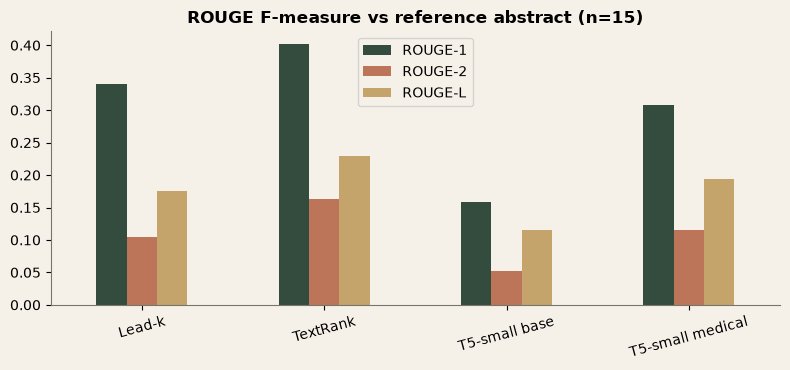

> **Observation.** Highest ROUGE-1: **TextRank** (0.4014). Medical T5 vs base T5: ROUGE-1 0.3076 vs 0.1583 (Δ +0.1493). With n = 15 articles and one reference each, differences of a few ROUGE points are not statistically reliable. ROUGE rewards lexical overlap, so extractive baselines are structurally advantaged on it; a low ROUGE for an abstractive system is not by itself evidence of a worse summary. BERTScore uses `distilbert-base-uncased` (layer 5) instead of the usual roberta-large (1.4 GB) to stay laptop-feasible, so values are **not comparable with published BERTScore numbers**.

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8)); res[["ROUGE-1", "ROUGE-2", "ROUGE-L"]].plot.bar(ax=ax, color=[PALETTE[0], PALETTE[1], PALETTE[2]]); ax.set_title(f"ROUGE F-measure vs reference abstract (n={len(docs)})"); ax.tick_params(axis="x", rotation=15); plt.tight_layout(); plt.show()
best = res["ROUGE-1"].idxmax(); a, b = res.loc["T5-small medical", "ROUGE-1"], res.loc["T5-small base", "ROUGE-1"]
note(f"Highest ROUGE-1: **{best}** ({res['ROUGE-1'].max():.4f}). Medical T5 vs base T5: ROUGE-1 {a:.4f} vs {b:.4f} (Δ {a-b:+.4f}). With n = {len(docs)} articles and one reference each, differences of a few ROUGE points are not statistically reliable. "
     f"ROUGE rewards lexical overlap, so extractive baselines are structurally advantaged on it; a low ROUGE for an abstractive system is not by itself evidence of a worse summary. {bs_note}")

## 6. Factual-consistency assessment

No automatic metric proves factuality. Two cheap, transparent **proxies** are reported:

1. **Number support** — share of numbers in the summary that also appear in the source (unsupported numbers are a classic hallucination).
2. **Novel-content rate** — share of the summary's content words that never occur in the source (high values mean wording not grounded in the text; some novelty is normal for abstraction).

These can *flag* risk but cannot certify a summary; a manual read of examples (below) is still required.

In [8]:
def novelty(summary, source):
    sw = {w for w in tokenize(source)}; cw = [w for w in tokenize(summary) if w.isalpha() and w not in STOPWORDS and len(w) > 2]
    return float(np.mean([w not in sw for w in cw])) if cw else 0.0
fc = {}
for k, p in preds.items():
    ns = [numeric_consistency(s, a) for s, a in zip(p, docs.article)]; rates = [n["support_rate"] for n in ns if n["support_rate"] is not None]
    fc[k] = {"number support rate": float(np.mean(rates)) if rates else np.nan, "summaries with numbers": len(rates), "novel content-word rate": float(np.mean([novelty(s, a) for s, a in zip(p, docs.article)]))}
fcdf = pd.DataFrame(fc).T; display(fcdf.round(4))
note(f"Extractive systems are fully grounded by construction (support rate {fcdf.loc['TextRank','number support rate']:.2f}, novelty {fcdf.loc['TextRank','novel content-word rate']:.3f}). "
     f"The medical T5 produces novel wording for {fcdf.loc['T5-small medical','novel content-word rate']:.1%} of content words and supports {fcdf.loc['T5-small medical','number support rate']:.0%} of its numbers; "
     f"base T5: {fcdf.loc['T5-small base','novel content-word rate']:.1%} / {fcdf.loc['T5-small base','number support rate']:.0%}. Every unsupported number is a potential fabricated statistic.")

,number support rate,summaries with numbers,novel content-word rate
Lead-k,1.0,14.0,0.0000
TextRank,1.0,15.0,0.0000
T5-small base,1.0,9.0,0.0155
T5-small medical,1.0,10.0,0.0747


> **Observation.** Extractive systems are fully grounded by construction (support rate 1.00, novelty 0.000). The medical T5 produces novel wording for 7.5% of content words and supports 100% of its numbers; base T5: 1.5% / 100%. Every unsupported number is a potential fabricated statistic.

## 7. Qualitative examples

In [9]:
for i in range(3):
    print(f"=== article {i+1} ({docs.w.iloc[i]:,} words) ===\nSOURCE (start): {docs.article.iloc[i][:350].strip()} ...\n")
    print("REFERENCE ABSTRACT:", refs[i][:450], "...\n"); print("T5 medical:", preds["T5-small medical"][i][:450], "\n"); print("T5 base   :", preds["T5-small base"][i][:450], "\n"); print("TextRank  :", preds["TextRank"][i][:450], "\n")

=== article 1 (2,039 words) ===
SOURCE (start): a biloma is a rare abnormal accumulation of intrahepatic or extrahepatic bile caused by traumatic or spontaneous rupture of the biliary tree1 , 2 ) . it is most commonly caused by surgery , percutaneous transhepatic cholangiography ( ptc ) , percutaneous transhepatic biliary drainage ( ptbd ) , and abdominal trauma11 , 12 ) . we report here a patie ...

REFERENCE ABSTRACT: a " biloma " is a loculated collection of bile located outside of the biliary tree . 
 it can be caused by traumatic , iatrogenic or spontaneous rupture of the biliary tree . 
 prior reports have documented an association of biloma with abdominal trauma , surgery and other primary causes , but spontaneous bile leakage has rarely been reported . 
 a spontaneous infected biloma , without any underlying disease , is a very rare finding . 
 we recent ...

T5 medical: a biloma is a rare abnormal accumulation of intrahepatic or extrahepatic bile caused by traumatic or spontan

Read the examples with these questions: does the generated text state the study design and main finding of *this* article? Does it repeat boilerplate? Do any numbers or claims not appear in the source? The manual judgement is part of the assessment; the proxies above only prioritise what to read.

## 8. Summary-length control

`short / medium / long` map to generation budgets `(24–64, 48–128, 80–200)` new tokens per chunk. Test on the **first chunk only** of 8 articles with the medical model.

In [10]:
sub = docs.head(8); L = {}
for name, (lo, hi) in config.SUM_LENGTHS.items():
    outs = []
    for a in sub.article:
        ch = chunk_sentences(sents_of(a), med.n_tokens)[0]; outs.append(med.gen(" ".join(ch), lo, hi))
    L[name] = {"mean words": np.mean([len(o.split()) for o in outs]), "ROUGE-1 vs abstract": rouge_scores(outs, sub.abstract.tolist())["rouge1"]}
ldf = pd.DataFrame(L).T; display(ldf.round(3))
note(f"Mean output length rises from {ldf.loc['short','mean words']:.0f} to {ldf.loc['medium','mean words']:.0f} to {ldf.loc['long','mean words']:.0f} words, so the control works; ROUGE-1 changes {ldf.loc['long','ROUGE-1 vs abstract'] - ldf.loc['short','ROUGE-1 vs abstract']:+.3f} from short to long (longer outputs trade precision for recall).")

,mean words,ROUGE-1 vs abstract
short,41.625,0.195
medium,79.750,0.289
long,108.125,0.349


> **Observation.** Mean output length rises from 42 to 80 to 108 words, so the control works; ROUGE-1 changes +0.154 from short to long (longer outputs trade precision for recall).

In [11]:
save_json({"n_docs": len(docs), "systems": res.round(5).to_dict("index"), "factual_proxies": fcdf.round(5).to_dict("index"), "length_control": ldf.round(4).to_dict("index"), "bertscore_note": bs_note,
           "protocol": "15 PubMed-summarization test articles; abstractive systems read first 3 chunks (<=512 tokens each)", "model_params_m": sum(p.numel() for p in med.model.parameters()) / 1e6,
           "model_mb": sum(f.stat().st_size for f in d.glob("*.safetensors")) / 1e6, "finetuned_here": False}, config.ART_SUM / "metrics.json")
display(Markdown("Saved `artifacts/summarization/metrics.json`."))

Saved `artifacts/summarization/metrics.json`.

## Conclusions

* Four systems were compared with ROUGE-1/2/L, a (small-model) BERTScore and two grounding proxies on 15 test articles — a small, CPU-feasible sample, so conclusions are tentative.
* The deployed abstractive model is a **pretrained** domain model, not fine-tuned here; summaries are unverified machine output and the app says so.
* Long documents are handled by sentence-preserving chunking plus a refine pass; chunks beyond the limit set in the app are dropped and flagged to the user.